# 05 - Variable Selection and Logistic Regression

**Goal:** choose the final set of WoE variables and fit the PD model (logistic regression), using the **development set only**. The hold-out set stays closed until notebook 07.

**Selection in layers**
1. **IV filter:** drop variables with almost no separating power.
2. **Correlation:** look for pairs of variables that carry the same information.
3. **Full model:** fit all variables with `statsmodels` and read coefficient **signs**, **p-values** and **VIF**.
4. **Backward elimination:** remove one variable at a time (wrong sign first, then high VIF, then high p-value).
5. **Business judgment:** the final set must make sense to a credit officer.

**Sign convention.** Target = 1 means *bad*, and WoE = ln(%good / %bad), so a higher WoE means a **safer** bin. A higher WoE must therefore lower the log-odds of default,
so every coefficient is expected to be **negative**. A positive coefficient is a wrong sign.

**No class weights, no SMOTE:** they would distort the predicted probabilities, and the model output must remain a real PD.

In [1]:
import sys, json
sys.path.insert(0, "../src")

from pathlib import Path
for _p in ("../data/processed", "../outputs/figures", "../outputs/metrics", "../outputs/scorecard"):
    Path(_p).mkdir(parents=True, exist_ok=True)   # Git does not keep empty folders

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from feature_engineering import WoEBinner, iv_strength
from modeling import fit_logit, vif_table, coef_table, backward_select, cv_metrics
from evaluation import discrimination_metrics

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

dev = pd.read_csv("../data/processed/dev.csv", index_col="id")
y = dev["target"]

with open("../outputs/scorecard/binning_spec.json") as f:
    spec = json.load(f)
binners = {v: WoEBinner.from_dict(s) for v, s in spec.items()}

# Replace every variable by its WoE value, using the bins learned in notebook 04
X = pd.DataFrame({f"woe_{v}": b.transform(dev[v]) for v, b in binners.items()})
assert not X.isna().any().any() and len(X) == len(dev)
print("WoE design matrix:", X.shape)
X.head()

WoE design matrix: (104987, 10)


,woe_revolving_util,woe_age,woe_n_30_59_late,woe_n_60_89_late,woe_n_90_late,woe_debt_ratio,woe_monthly_income,woe_n_open_lines,woe_n_real_estate,woe_n_dependents
id,,,,,,,,,,
2,-1.199705,-0.358542,0.526839,0.284274,0.391148,0.107622,-0.391042,0.057160,-0.239161,-0.128200
3,-0.399738,-0.358542,-0.889885,0.284274,-1.969738,0.107622,-0.391042,-0.354229,-0.239161,0.149932
4,0.670110,-0.498284,0.526839,0.284274,0.391148,0.107622,-0.391042,0.057160,-0.239161,0.149932
5,-1.199705,-0.162539,-0.889885,0.284274,0.391148,0.107622,0.440557,0.142735,0.259039,0.149932
6,0.670110,1.112826,0.526839,0.284274,0.391148,0.107622,-0.231014,-0.178044,0.259039,-0.128200


## 1. IV filter

In [2]:
iv = pd.DataFrame({"variable": [f"woe_{v}" for v in binners], "iv": [b.iv_ for b in binners.values()]})
iv["strength"] = iv["iv"].map(iv_strength)
iv["keep_at_iv_0.02"] = iv["iv"] >= 0.02
iv.sort_values("iv", ascending=False).reset_index(drop=True)

,variable,iv,strength,keep_at_iv_0.02
0,woe_revolving_util,1.156586,very strong (check for leakage),True
1,woe_n_90_late,0.883762,very strong (check for leakage),True
2,woe_n_30_59_late,0.735913,very strong (check for leakage),True
3,woe_n_60_89_late,0.590217,very strong (check for leakage),True
4,woe_age,0.269891,medium,True
5,woe_n_open_lines,0.099101,weak,True
6,woe_monthly_income,0.082434,weak,True
7,woe_debt_ratio,0.079622,weak,True
8,woe_n_real_estate,0.061841,weak,True
9,woe_n_dependents,0.038921,weak,True


All ten variables pass the minimal IV threshold (0.02), so nobody is removed at this layer.

## 2. Correlation between WoE variables

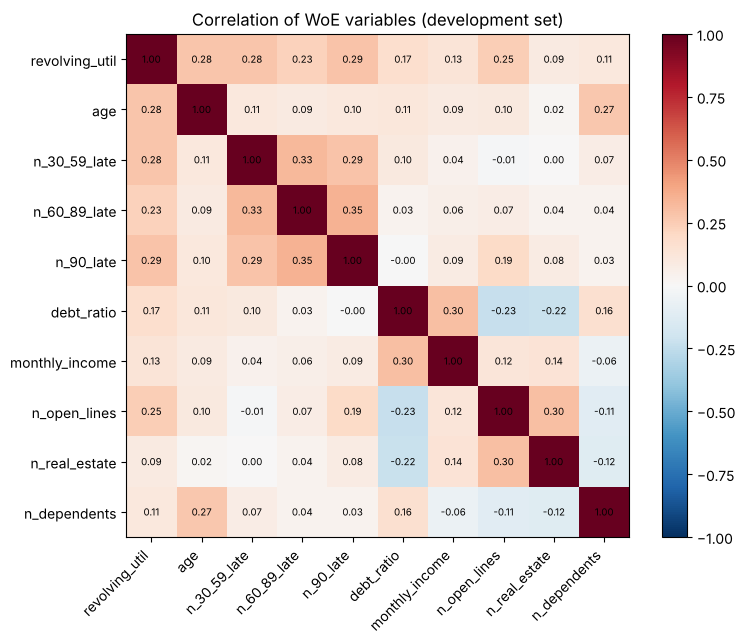

Pairs with |correlation| > 0.5: 0
Largest absolute correlation: ('woe_n_60_89_late', 'woe_n_90_late') 0.345


In [3]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
labels = [c.replace("woe_", "") for c in corr.columns]
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); ax.set_title("Correlation of WoE variables (development set)")
plt.tight_layout(); plt.savefig("../outputs/figures/woe_correlation.png", dpi=130); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print("Pairs with |correlation| > 0.5:", int((pairs.abs() > 0.5).sum()))
print("Largest absolute correlation:", pairs.abs().idxmax(), round(pairs.abs().max(), 3))

**Reading:** no pair exceeds 0.5. The three delinquency counts correlate with each other only moderately (0.29-0.35), so none of them is a duplicate of another. No variable is removed at this layer.

## 3. Full model: signs, p-values, VIF

In [4]:
full = fit_logit(X, y)
t = coef_table(full)
t["vif"] = vif_table(X)
t.round(4)

,coef,std_err,z,p_value,sign_ok,vif
const,-2.6059,0.0151,-172.2096,0.0000,True,NaN
woe_revolving_util,-0.5989,0.0146,-41.0871,0.0000,True,1.3395
woe_age,-0.4151,0.0313,-13.2522,0.0000,True,1.1719
woe_n_30_59_late,-0.4845,0.0161,-30.1132,0.0000,True,1.2241
woe_n_60_89_late,-0.3711,0.0172,-21.6099,0.0000,True,1.2240
woe_n_90_late,-0.5345,0.0138,-38.6988,0.0000,True,1.2588
woe_debt_ratio,-0.9153,0.0544,-16.8230,0.0000,True,1.3384
woe_monthly_income,0.0212,0.0525,0.4041,0.6862,False,1.1979
woe_n_open_lines,-0.1075,0.0479,-2.2448,0.0248,True,1.2969
woe_n_real_estate,-0.6737,0.0608,-11.0827,0.0000,True,1.1713


**Reading:**
- Nine of ten coefficients are negative (expected) and significant at the 5% level (all but `n_open_lines` with p < 0.003).
- `woe_monthly_income` has the **wrong sign** (+0.02) and a p-value of 0.69: after controlling for the other variables it adds nothing.
  Its information is already carried by `debt_ratio` (correlation 0.30) and `age`, and its Missing group is identical to the one of `debt_ratio`.
- VIF is below 1.4 everywhere, so there is no multicollinearity problem. This also confirms that the shared Missing groups found in notebook 03
  (income/debt ratio; the three late counts) do not make the WoE columns collinear. The three late-count variables all stay in the model, so the
  risk of the 96/98 special-code group is carried jointly by their three Missing bins.

## 4. Backward elimination

In [5]:
kept, final, log = backward_select(X, y, alpha=0.05, max_vif=5.0, expected_sign=-1)
print("Variables kept:", len(kept), "of", X.shape[1])
log

Variables kept: 9 of 10


,step,dropped,reason,value,n_left
0,1,woe_monthly_income,wrong sign,0.686161,9


In [6]:
final_tbl = coef_table(final)
final_tbl["vif"] = vif_table(X[kept])
final_tbl.round(4)

,coef,std_err,z,p_value,sign_ok,vif
const,-2.6058,0.0151,-172.2601,0.0000,True,NaN
woe_revolving_util,-0.5986,0.0146,-41.1115,0.0000,True,1.3395
woe_age,-0.4135,0.0311,-13.3089,0.0000,True,1.1684
woe_n_30_59_late,-0.4847,0.0161,-30.1247,0.0000,True,1.2240
woe_n_60_89_late,-0.3709,0.0172,-21.6071,0.0000,True,1.2237
woe_n_90_late,-0.5341,0.0138,-38.7532,0.0000,True,1.2568
woe_debt_ratio,-0.9079,0.0512,-17.7169,0.0000,True,1.1698
woe_n_open_lines,-0.1048,0.0474,-2.2096,0.0271,True,1.2744
woe_n_real_estate,-0.6708,0.0604,-11.1062,0.0000,True,1.1398
woe_n_dependents,-0.2279,0.0730,-3.1210,0.0018,True,1.1275


**Reading:** one step only. `woe_monthly_income` is dropped (wrong sign, p = 0.69). All remaining coefficients are negative, significant at the 5% level, and VIF stays below 1.4.
`n_open_lines` is the weakest survivor (p = 0.027, IV 0.099); it is kept because it is statistically significant, has the expected sign and a clear business meaning (thin credit history is risky).

**Why are the coefficients between -0.1 and -0.9 and not close to -1?** If a single WoE variable were the whole model, its coefficient would be close to -1 (WoE is already a log-odds ratio).
With several partially overlapping variables, each one's coefficient shrinks accordingly. What matters is that **none has a wrong sign**.

## 5. Performance on the development set

In [7]:
p_dev = final.predict()                                    # in-sample PD
ins = discrimination_metrics(y, p_dev)
cv = cv_metrics(X[kept], y, n_splits=5, seed=42)
print("In-sample :", {k: round(v, 4) for k, v in ins.items()})
display(cv.round(4))
cv[["auc", "gini", "ks"]].agg(["mean", "std"]).round(4)

In-sample : {'auc': 0.8584, 'gini': 0.7168, 'ks': 0.5539}


,fold,auc,gini,ks
0,1,0.8634,0.7267,0.5609
1,2,0.8542,0.7084,0.5493
2,3,0.8558,0.7116,0.5565
3,4,0.8494,0.6987,0.5433
4,5,0.8683,0.7366,0.5786


,auc,gini,ks
mean,0.8582,0.7164,0.5577
std,0.0076,0.0151,0.0135


**Reading:** in-sample AUC (~0.858) and the 5-fold cross-validated mean (~0.858) are essentially the same, with a small fold-to-fold spread (std of AUC ~0.008).
That means no sign of overfitting, which is expected for a 9-variable logistic regression on 105k rows.
The AUC is in the normal range for this dataset (0.85-0.86) and nowhere near 0.95, so there is no sign of leakage.

*Caveat:* the bins were learned on the whole development set and are not re-learned inside each fold, so the cross-validated numbers are very slightly optimistic. The real test is the hold-out set in notebook 07.

In [8]:
print(f"Mean predicted PD = {p_dev.mean():.4%} | development bad rate = {y.mean():.4%}")

Mean predicted PD = 6.6865% | development bad rate = 6.6865%


A logistic regression with an intercept reproduces the sample bad rate exactly. This is the first calibration check; we do not need `class_weight` or resampling to get there.

## 6. Hand check: from WoE values to PD

Compute one customer's PD **by hand** from the coefficients and compare it with the model.

In [9]:
row = X[kept].iloc[0]
log_odds = final.params["const"] + (final.params[kept] * row).sum()
pd_manual = 1 / (1 + np.exp(-log_odds))
print(pd.DataFrame({"woe": row, "coef": final.params[kept], "contribution": final.params[kept] * row}).round(4))
print(f"\nlog-odds = {log_odds:.4f} -> PD = 1 / (1 + exp(-log-odds)) = {pd_manual:.4%}")
print(f"model.predict() for the same row = {p_dev[0]:.4%}")
assert np.isclose(pd_manual, p_dev[0])

                       woe    coef  contribution
woe_revolving_util -1.1997 -0.5986        0.7182
woe_age            -0.3585 -0.4135        0.1483
woe_n_30_59_late    0.5268 -0.4847       -0.2553
woe_n_60_89_late    0.2843 -0.3709       -0.1054
woe_n_90_late       0.3911 -0.5341       -0.2089
woe_debt_ratio      0.1076 -0.9079       -0.0977
woe_n_open_lines    0.0572 -0.1048       -0.0060
woe_n_real_estate  -0.2392 -0.6708        0.1604
woe_n_dependents   -0.1282 -0.2279        0.0292

log-odds = -2.2231 -> PD = 1 / (1 + exp(-log-odds)) = 9.7699%
model.predict() for the same row = 9.7699%


## 7. Save the model

In [10]:
coefs = coef_table(final).drop(columns="sign_ok")
coefs["vif"] = vif_table(X[kept])
coefs.to_csv("../outputs/scorecard/model_coefficients.csv")
model_spec = {
    "intercept": float(final.params["const"]),
    "coefficients": {c.replace("woe_", ""): float(final.params[c]) for c in kept},
    "dropped": log.to_dict(orient="records"),
    "sign_convention": "target=1 is bad; WoE=ln(%good/%bad); coefficients are negative",
}
with open("../outputs/scorecard/model_spec.json", "w") as f:
    json.dump(model_spec, f, indent=2)
log.to_csv("../outputs/metrics/selection_log.csv", index=False)
pd.concat([pd.DataFrame([{"fold": "in-sample", **ins}]), cv.assign(fold=cv["fold"].astype(str))]).to_csv("../outputs/metrics/dev_metrics.csv", index=False)
print("Saved model_coefficients.csv, model_spec.json, selection_log.csv, dev_metrics.csv")

Saved model_coefficients.csv, model_spec.json, selection_log.csv, dev_metrics.csv


## Summary

- Final model: **9 WoE variables** (all except `monthly_income`) in an unweighted logistic regression; all coefficients negative, all significant at 5%, VIF < 1.4.
- Development performance: AUC ~0.858, Gini ~0.717, KS ~0.554; 5-fold CV agrees (no overfitting).
- Hold-out set untouched.

**Questions to answer in your own words (interview material)**
1. Why must every coefficient be negative here? What would you conclude if one were positive?
2. Why did `monthly_income` end up with a useless coefficient even though income matters in credit?
3. Why is it wrong to use `class_weight="balanced"` for a PD model?

Next: notebook 06 - convert the model to a **scorecard** (points per bin with PDO scaling); notebook 07 then validates it on the hold-out set (AUC, Gini, KS, rank ordering, calibration, cut-off).